# XGBoost Sampling Strategy Comparison

Train and compare XGBoost models with several class-imbalance strategies. This notebook is independent of `03-xg-boost.ipynb` and uses the existing cleaned dataset without changing it.

## Local Dependencies

Install the Python packages used in this notebook into the active local Jupyter environment.

In [25]:
%pip install pandas scikit-learn matplotlib xgboost imbalanced-learn

## Data Loading

Load the shared cleaned dataset through its Google Drive URL. The URL helper is defined in this notebook so it does not depend on importing project-local utilities.

In [26]:
clean_dataset_drive_url = "https://drive.google.com/file/d/1AxchD_W4q0d9lXBOi2gyqunl_TmH3ktm/view?usp=sharing"

In [27]:
import re


def drive_to_direct_url(link: str) -> str:
    patterns = [
        r"/file/d/([a-zA-Z0-9_-]+)",
        r"id=([a-zA-Z0-9_-]+)",
        r"/open\?id=([a-zA-Z0-9_-]+)",
    ]

    for pattern in patterns:
        match = re.search(pattern, link)
        if match:
            return f"https://drive.google.com/uc?id={match.group(1)}"

    raise ValueError("Invalid Google Drive share URL.")

In [28]:
import pandas as pd

df = pd.read_csv(drive_to_direct_url(clean_dataset_drive_url))

In [29]:
df.head()

,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,17.79,0,0,0,0,0,No


## Model Input Setup

Use the same target, numerical features, and categorical feature as the existing Logistic Regression and XGBoost workflows.

In [30]:
target_col = "diabetic"
numerical_cols = ["pulse_rate", "systolic_bp", "diastolic_bp", "glucose", "bmi"]
categorical_cols = ["gender"]

X = df.drop(columns=[target_col])
y = df[target_col].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("The target contains labels other than 'No' and 'Yes'.")

## Train-Test Split

Match the existing notebooks' stratified 80/20 split. Keep the test partition out of preprocessing, resampling, and model selection.

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

In [32]:
y_train.value_counts().rename(index={0: "No Diabetes", 1: "Diabetes"})

,count
diabetic,
No Diabetes,3934
Diabetes,274


## Training Pipeline Setup

Sampling is placed inside an imbalanced-learn pipeline, so it is fit only on each training fold and never on validation or test data.

In [33]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

### Cross-Validation Strategy

Use the same five shuffled stratified folds and fixed random state for all strategies. F1-score focuses selection on positive-class detection under the observed class imbalance.

In [34]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

### Feature Encoding and Scaling

Keep preprocessing inside each pipeline so it is fitted independently within each cross-validation training fold.

In [35]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="first"),
            categorical_cols,
        ),
    ]
)

### XGBoost Model

Use CPU histogram trees for local training. The estimator uses one thread so grid-search parallelism controls resource use.

In [36]:
xgb_model = XGBClassifier(
    learning_rate=0.05,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=1,
)

### Sampling Strategies

Compare a no-sampling baseline, random over-sampling, random under-sampling, and SMOTE. The two sampling ratios test partial balancing (0.5) against full balancing (1.0); fixed sampler seeds keep results reproducible.

In [37]:
sampling_strategies = {
    "Baseline (No Sampling)": "passthrough",
    "Random Over-Sampling": RandomOverSampler(random_state=42),
    "Random Under-Sampling": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
}

In [38]:
pipelines = {
    name: Pipeline(
        [
            ("preprocessor", preprocessor),
            ("sampler", sampler),
            ("classifier", clone(xgb_model)),
        ]
    )
    for name, sampler in sampling_strategies.items()
}

## Hyperparameter Tuning

Search a compact common XGBoost grid for every pipeline. Sampling methods additionally compare 0.5 and 1.0 minority-to-majority ratios; keeping the tree grid small limits local CPU training time.

In [39]:
param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [3, 4, 5],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0],
}

In [40]:
grid_searches = {}
for name, pipeline in pipelines.items():
    strategy_param_grid = dict(param_grid)
    if name != "Baseline (No Sampling)":
        strategy_param_grid["sampler__sampling_strategy"] = [0.5, 1.0]

    grid_searches[name] = GridSearchCV(
        estimator=pipeline,
        param_grid=strategy_param_grid,
        cv=cv,
        scoring="f1",
        n_jobs=-1,
        refit=True,
    )

In [41]:
for grid_search in grid_searches.values():
    grid_search.fit(X_train, y_train)

In [42]:
cv_results = pd.DataFrame(
    [
        {
            "Sampling Strategy": name,
            "Best CV F1": grid_search.best_score_,
            "Best Parameters": grid_search.best_params_,
        }
        for name, grid_search in grid_searches.items()
    ]
).sort_values("Best CV F1", ascending=False, ignore_index=True)
cv_results.round(4)

,Sampling Strategy,Best CV F1,Best Parameters
0,Random Over-Sampling,0.3869,"{'classifier__colsample_bytree': 0.8, 'classif..."
1,Random Under-Sampling,0.3639,"{'classifier__colsample_bytree': 0.8, 'classif..."
2,SMOTE,0.3572,"{'classifier__colsample_bytree': 1.0, 'classif..."
3,Baseline (No Sampling),0.2226,"{'classifier__colsample_bytree': 0.8, 'classif..."


## Test-Set Evaluation

Use each grid search's best estimator, refitted only on the training split, for evaluation on the same untouched test set. Choose the top sampling strategy by cross-validation F1, not by test results.

In [43]:
best_sampling_strategy = max(
    (
        name
        for name in grid_searches
        if name != "Baseline (No Sampling)"
    ),
    key=lambda name: grid_searches[name].best_score_,
)
models = {
    name: grid_search.best_estimator_
    for name, grid_search in grid_searches.items()
}

In [44]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_classifiers(models, X_test, y_test):
    results = {}
    for model_name, model in models.items():
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        tn, fp, fn, tp = confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        ).ravel()

        results[model_name] = {
            "Accuracy": accuracy_score(y_test, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Sensitivity (Recall)": recall_score(y_test, y_pred, zero_division=0),
            "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
            "NPV": tn / (tn + fn) if (tn + fn) else 0.0,
            "F1-Score": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "PR-AUC": average_precision_score(y_test, y_prob),
            "Brier Score": brier_score_loss(y_test, y_prob),
            "MCC": matthews_corrcoef(y_test, y_pred),
            "Cohen's Kappa": cohen_kappa_score(y_test, y_pred),
            "True Negative": tn,
            "False Positive": fp,
            "False Negative": fn,
            "True Positive": tp,
        }

    return pd.DataFrame(results).round(4)

In [45]:
evaluation_results = evaluate_classifiers(models, X_test, y_test)
evaluation_results

,Baseline (No Sampling),Random Over-Sampling,Random Under-Sampling,SMOTE
Accuracy,0.9364,0.9259,0.9183,0.9183
Balanced Accuracy,0.5827,0.7208,0.7441,0.6894
Precision,0.5217,0.4342,0.4022,0.3816
Sensitivity (Recall),0.1765,0.4853,0.5441,0.4265
Specificity,0.9888,0.9563,0.9442,0.9523
NPV,0.9456,0.9642,0.9677,0.9601
F1-Score,0.2637,0.4583,0.4625,0.4028
ROC-AUC,0.8304,0.8653,0.8593,0.8335
PR-AUC,0.2975,0.3924,0.3917,0.3701
Brier Score,0.0540,0.0834,0.0920,0.0910


### Best Sampling Strategy vs. Baseline

Compare the baseline with the sampling strategy selected using training-only cross-validation. All strategies are also available in the full test evaluation table above.

In [46]:
comparison_models = ["Baseline (No Sampling)", best_sampling_strategy]
comparison_metrics = evaluation_results.loc[
    [
        "Accuracy",
        "Precision",
        "Sensitivity (Recall)",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC",
    ],
    comparison_models,
].T
comparison_metrics

,Accuracy,Precision,Sensitivity (Recall),F1-Score,ROC-AUC,PR-AUC
Baseline (No Sampling),0.9364,0.5217,0.1765,0.2637,0.8304,0.2975
Random Over-Sampling,0.9259,0.4342,0.4853,0.4583,0.8653,0.3924


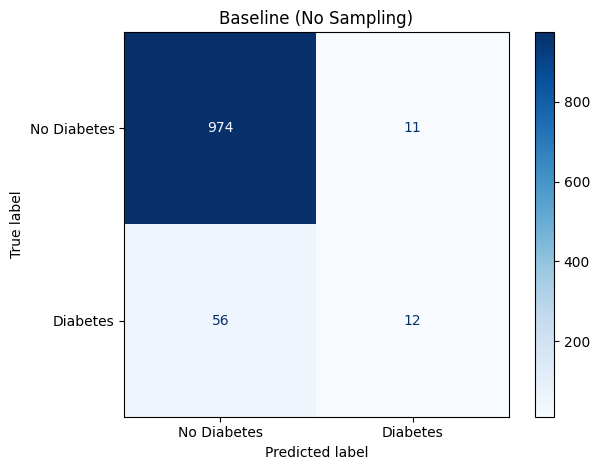

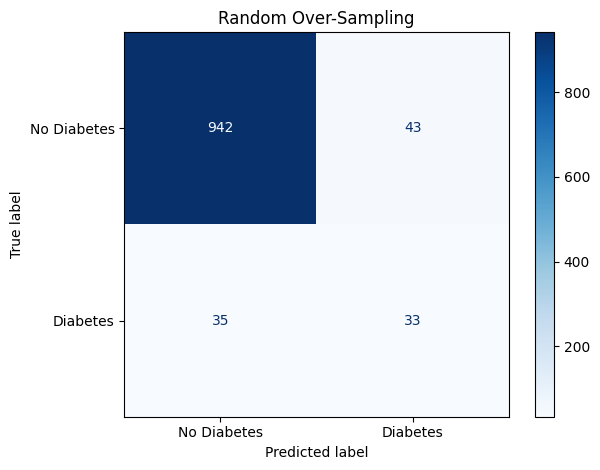

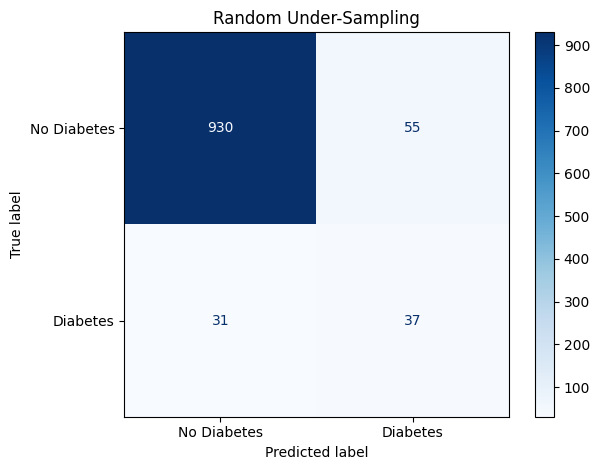

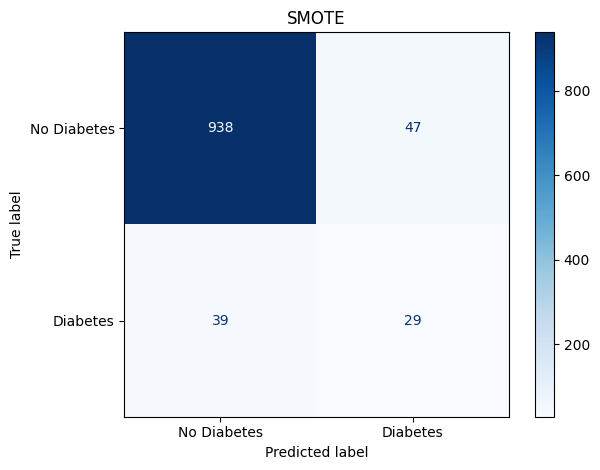

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model.predict(X_test),
        display_labels=["No Diabetes", "Diabetes"],
        cmap="Blues",
    )
    plt.title(name)
    plt.tight_layout()
    plt.show()

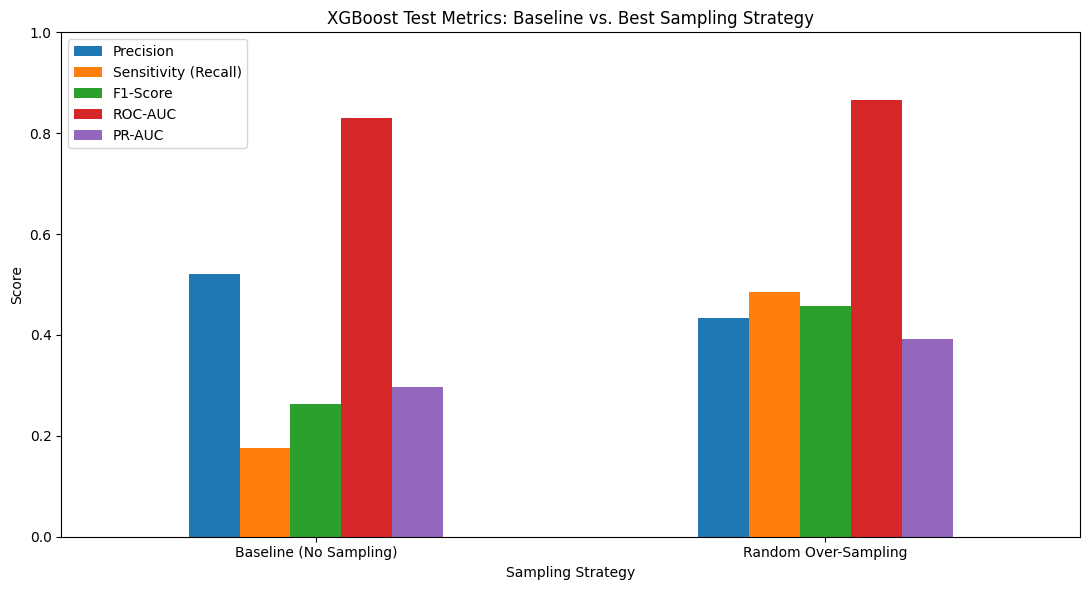

In [48]:
comparison_metrics[
    ["Precision", "Sensitivity (Recall)", "F1-Score", "ROC-AUC", "PR-AUC"]
].plot(kind="bar", figsize=(11, 6))
plt.title("XGBoost Test Metrics: Baseline vs. Best Sampling Strategy")
plt.ylabel("Score")
plt.xlabel("Sampling Strategy")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()